# M&A Post-Mortem: Agnico Eagle & Kirkland Lake Gold Merger

This project analyzes the 2021-2022 merger of equals between Agnico Eagle Mines (AEM) and 
Kirkland Lake Gold (KL) — a $13.5B all-stock combination that created one of the world's 
largest gold producers. The goal is to reconstruct the deal terms, evaluate whether the 
market's initial skepticism (KL shares fell 7.7% on announcement) was justified, and assess 
whether the promised synergies ($0.8B over 5 years) have materialized in the combined 
company's financials.

In [13]:
import pandas as pd
import yfinance as yf
from sqlalchemy import create_engine
import matplotlib.pyplot as plt

engine = create_engine("sqlite:///../data/ma_deal.db")

In [4]:
aem = yf.Ticker("AEM")
aem_hist = aem.history(start="2021-08-01", end="2026-08-15")
aem_hist = aem_hist.reset_index()

print(f"Number of rows: {len(aem_hist)}")
aem_hist.tail()

Number of rows: 1265


,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
1260,2026-08-10 00:00:00-04:00,178.389999,181.619995,174.649994,180.479996,3544100,0.0,0.0
1261,2026-08-11 00:00:00-04:00,180.000000,183.639999,179.259995,181.750000,2442900,0.0,0.0
1262,2026-08-12 00:00:00-04:00,186.800003,187.990005,183.770004,185.179993,3387300,0.0,0.0
1263,2026-08-13 00:00:00-04:00,182.149994,182.899994,178.000000,180.360001,3767000,0.0,0.0
1264,2026-08-14 00:00:00-04:00,182.899994,187.880005,182.259995,186.460007,2901200,0.0,0.0


In [ ]:
aem_hist["ticker"] = "AEM"
aem_hist.to_sql("prices", engine, if_exists="replace", index=False)

announcement_price = aem_hist[aem_hist["Date"].dt.date == pd.Timestamp("2021-09-28").date()]["Close"]
latest_price = aem_hist["Close"].iloc[-1]

print(f"AEM price on announcement day (2021-09-28): ${announcement_price.values[0]:.2f}" if len(announcement_price) > 0 else "Date not found, checking nearby dates")
print(f"AEM price today: ${latest_price:.2f}")

AEM price on announcement day (2021-09-28): $44.42
AEM price today: $186.46


In [6]:
peers = ["NEM", "GOLD"]
peer_returns = {}

for ticker in peers:
    peer = yf.Ticker(ticker)
    peer_hist = peer.history(start="2021-09-28", end="2026-08-15")
    start_price = peer_hist["Close"].iloc[0]
    end_price = peer_hist["Close"].iloc[-1]
    peer_returns[ticker] = (end_price / start_price - 1) * 100

aem_return = (latest_price / announcement_price.values[0] - 1) * 100

print(f"AEM return since announcement: {aem_return:.1f}%")
for ticker, ret in peer_returns.items():
    print(f"{ticker} return over same period: {ret:.1f}%")

AEM return since announcement: 319.8%
NEM return over same period: 147.1%
GOLD return over same period: 79.3%


In [7]:
aem_financials = {
    "income": aem.financials,
    "balance": aem.balance_sheet,
    "cashflow": aem.cashflow,
}

total_rows = 0
for source, df_raw in aem_financials.items():
    if df_raw is None or df_raw.empty:
        continue
    df_long = df_raw.stack().reset_index()
    df_long.columns = ["item", "fiscal_date", "value"]
    df_long["ticker"] = "AEM"
    df_long["source"] = source
    df_long.to_sql("financial_statements", engine, if_exists="append", index=False)
    total_rows += len(df_long)

print(f"AEM: {total_rows} financial statement rows saved")

AEM: 1020 financial statement rows saved


In [9]:
query_items = """
SELECT DISTINCT item
FROM financial_statements
WHERE ticker = 'AEM'
  AND source = 'income'
ORDER BY item
"""

pd.read_sql(query_items, engine)

,item
0,Average Dilution Earnings
1,Basic Average Shares
2,Basic EPS
3,Cost Of Revenue
4,Diluted Average Shares
5,Diluted EPS
6,Diluted NI Availto Com Stockholders
7,EBIT
8,EBITDA
9,Gain On Sale Of Ppe


In [10]:
query_margins = """
SELECT item, fiscal_date, value
FROM financial_statements
WHERE ticker = 'AEM'
  AND source = 'income'
  AND item IN ('Total Revenue', 'Cost Of Revenue', 'Operating Income', 'EBITDA', 'Net Income')
ORDER BY item, fiscal_date DESC
"""

margins_data = pd.read_sql(query_margins, engine)
margins_data

,item,fiscal_date,value
0,Cost Of Revenue,2025-12-31 00:00:00.000000,4.985981e+09
1,Cost Of Revenue,2024-12-31 00:00:00.000000,4.600156e+09
2,Cost Of Revenue,2023-12-31 00:00:00.000000,4.425034e+09
3,Cost Of Revenue,2022-12-31 00:00:00.000000,3.738012e+09
4,Cost Of Revenue,2021-12-31 00:00:00.000000,NaN
5,EBITDA,2025-12-31 00:00:00.000000,8.382650e+09
6,EBITDA,2024-12-31 00:00:00.000000,4.422108e+09
7,EBITDA,2023-12-31 00:00:00.000000,3.942056e+09
8,EBITDA,2022-12-31 00:00:00.000000,2.271487e+09
9,EBITDA,2021-12-31 00:00:00.000000,NaN


In [11]:
pivot_margins = margins_data.pivot_table(
    index="fiscal_date",
    columns="item",
    values="value"
).reset_index()

pivot_margins["Operating_Margin"] = pivot_margins["Operating Income"] / pivot_margins["Total Revenue"] * 100
pivot_margins["EBITDA_Margin"] = pivot_margins["EBITDA"] / pivot_margins["Total Revenue"] * 100
pivot_margins["Net_Margin"] = pivot_margins["Net Income"] / pivot_margins["Total Revenue"] * 100
pivot_margins["Cost_Ratio"] = pivot_margins["Cost Of Revenue"] / pivot_margins["Total Revenue"] * 100

pivot_margins[["fiscal_date", "Total Revenue", "Operating_Margin", "EBITDA_Margin", "Net_Margin", "Cost_Ratio"]]

item,fiscal_date,Total Revenue,Operating_Margin,EBITDA_Margin,Net_Margin,Cost_Ratio
0,2022-12-31 00:00:00.000000,5.741162e+09,25.132700,39.564935,11.674448,65.108980
1,2023-12-31 00:00:00.000000,6.626909e+09,25.571997,59.485591,29.294306,66.773725
2,2024-12-31 00:00:00.000000,8.285753e+09,38.010172,53.370020,22.877595,55.518865
3,2025-12-31 00:00:00.000000,1.190785e+10,53.141083,70.395993,37.466550,41.871375


## Post-Merger Margin Analysis

Tracking Operating, EBITDA, and Net Margin from 2022 (first full year post-merger) through 2025 
to assess whether the promised synergies ($0.8B over 5 years) materialized operationally.

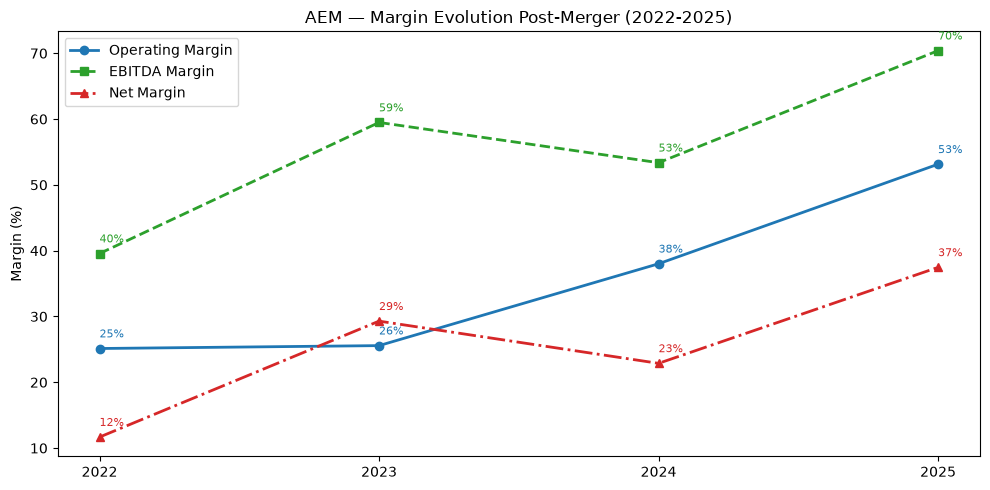

In [17]:
fig, ax = plt.subplots(figsize=(10, 5))

years = pivot_margins["fiscal_date"].str[:4].astype(int)

ax.plot(years, pivot_margins["Operating_Margin"], marker="o", linestyle="-", label="Operating Margin", color="#1f77b4", linewidth=2)
ax.plot(years, pivot_margins["EBITDA_Margin"], marker="s", linestyle="--", label="EBITDA Margin", color="#2ca02c", linewidth=2)
ax.plot(years, pivot_margins["Net_Margin"], marker="^", linestyle="-.", label="Net Margin", color="#d62728", linewidth=2)

# Adiciona o valor numérico em cada ponto
for series, color in [("Operating_Margin", "#1f77b4"), ("EBITDA_Margin", "#2ca02c"), ("Net_Margin", "#d62728")]:
    for x, y in zip(years, pivot_margins[series]):
        ax.annotate(f"{y:.0f}%", (x, y), textcoords="offset points", xytext=(0, 8), fontsize=8, color=color)

ax.set_title("AEM — Margin Evolution Post-Merger (2022-2025)")
ax.set_ylabel("Margin (%)")
ax.set_xticks(years)
ax.legend()
plt.tight_layout()
plt.show()

In [15]:
pivot_margins[["fiscal_date", "Operating_Margin", "EBITDA_Margin", "Net_Margin"]]

item,fiscal_date,Operating_Margin,EBITDA_Margin,Net_Margin
0,2022-12-31 00:00:00.000000,25.132700,39.564935,11.674448
1,2023-12-31 00:00:00.000000,25.571997,59.485591,29.294306
2,2024-12-31 00:00:00.000000,38.010172,53.370020,22.877595
3,2025-12-31 00:00:00.000000,53.141083,70.395993,37.466550


All three margins expanded meaningfully from 2022 to 2025 — EBITDA Margin from 40% to 70%, 
Operating Margin from 25% to 53%, Net Margin from 12% to 37%. The acceleration is most visible 
from 2024 onward, consistent with the timeline of the $0.8B synergy target promised over the 
first 5 years post-merger (2021–2026).